In [38]:
import pandas as pd

In [39]:
df = pd.read_csv("Loan_default.csv") # Load the data set in a variable

In [40]:
df.head() # Display the head

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [41]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='str')

In [42]:
df.shape

(255347, 18)

In [43]:
df["Default"].value_counts() # Find the total counts

Default
0    225694
1     29653
Name: count, dtype: int64

In [44]:
df["Default"].value_counts(normalize=True) * 100 # Put them into percentage, for balancing

Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64

In [45]:
df.isnull().sum() # Check if there is any missing values to use KNN

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

In [46]:
# Match the numeric features to a list
numeric_features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio"
]

In [47]:
# Match the categorical features to a list
categorical_features = [
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

In [48]:
# Find the mean values of the numeric features to determine it is okay to test
df.groupby("Default")[numeric_features].mean()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
Default,,,,,,,,,
0,44.409962,83899.165995,125353.656017,576.232270,60.764721,2.489566,13.176994,36.022544,0.498602
1,36.559539,71844.722659,144515.311469,559.286143,50.235457,2.588338,15.896227,36.051394,0.512467


In [49]:
# Find the mean values of the categorical features to determine it is okay to test
df.groupby("Education")["Default"].mean()

Education
Bachelor's     0.121011
High School    0.128789
Master's       0.108717
PhD            0.105860
Name: Default, dtype: float64

In [50]:
df.groupby("EmploymentType")["Default"].mean()

EmploymentType
Full-time        0.094634
Part-time        0.119652
Self-employed    0.114620
Unemployed       0.135529
Name: Default, dtype: float64

In [51]:
df.groupby("Education")["Default"].mean().sort_values(ascending=False)

Education
High School    0.128789
Bachelor's     0.121011
Master's       0.108717
PhD            0.105860
Name: Default, dtype: float64

In [52]:
df.groupby("EmploymentType")["Default"].mean().sort_values(ascending=False)

EmploymentType
Unemployed       0.135529
Part-time        0.119652
Self-employed    0.114620
Full-time        0.094634
Name: Default, dtype: float64

In [53]:
categorical_features = [
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

for feature in categorical_features:
    print(f"\nDefault rate by {feature}:")
    print(df.groupby(feature)["Default"].mean().sort_values(ascending=False))


Default rate by Education:
Education
High School    0.128789
Bachelor's     0.121011
Master's       0.108717
PhD            0.105860
Name: Default, dtype: float64

Default rate by EmploymentType:
EmploymentType
Unemployed       0.135529
Part-time        0.119652
Self-employed    0.114620
Full-time        0.094634
Name: Default, dtype: float64

Default rate by MaritalStatus:
MaritalStatus
Divorced    0.125328
Single      0.119124
Married     0.103972
Name: Default, dtype: float64

Default rate by HasMortgage:
HasMortgage
No     0.123451
Yes    0.108806
Name: Default, dtype: float64

Default rate by HasDependents:
HasDependents
No     0.127244
Yes    0.105024
Name: Default, dtype: float64

Default rate by LoanPurpose:
LoanPurpose
Business     0.123260
Auto         0.118814
Education    0.118381
Other        0.117885
Home         0.102348
Name: Default, dtype: float64

Default rate by HasCoSigner:
HasCoSigner
No     0.128661
Yes    0.103601
Name: Default, dtype: float64


In [54]:
features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio",
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

target = "Default"

X = df[features]
y = df[target]

In [55]:
X_encoded = pd.get_dummies(X, drop_first=True) # Useful to match reach row to the specific category, dummy encoding

In [56]:
X_encoded.head() # Show the new rows with the correct identified feature

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education_High School,...,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other,HasCoSigner_Yes
0,56,85994,50587,520,80,4,15.23,36,0.44,False,...,False,False,False,True,True,False,False,False,True,True
1,69,50432,124440,458,15,1,4.81,60,0.68,False,...,False,True,False,False,False,False,False,False,True,True
2,46,84208,129188,451,26,3,21.17,24,0.31,False,...,True,False,False,True,True,False,False,False,False,False
3,32,31713,44799,743,0,3,7.07,24,0.23,True,...,False,True,False,False,False,True,False,False,False,False
4,60,20437,9139,633,8,4,6.51,48,0.73,False,...,True,False,False,False,True,False,False,False,False,False


In [57]:
X_encoded.dtypes # Check if all types are correct

Age                               int64
Income                            int64
LoanAmount                        int64
CreditScore                       int64
MonthsEmployed                    int64
NumCreditLines                    int64
InterestRate                    float64
LoanTerm                          int64
DTIRatio                        float64
Education_High School              bool
Education_Master's                 bool
Education_PhD                      bool
EmploymentType_Part-time           bool
EmploymentType_Self-employed       bool
EmploymentType_Unemployed          bool
MaritalStatus_Married              bool
MaritalStatus_Single               bool
HasMortgage_Yes                    bool
HasDependents_Yes                  bool
LoanPurpose_Business               bool
LoanPurpose_Education              bool
LoanPurpose_Home                   bool
LoanPurpose_Other                  bool
HasCoSigner_Yes                    bool
dtype: object

In [58]:
print(X_encoded.shape)
print(y.shape)

(255347, 24)
(255347,)


In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size = 0.2, random_state=0, stratify=y) # Setting up configuration, stratify helps keep same class balance 

In [60]:
# Using Logistic Regression
from sklearn.linear_model import LogisticRegression 

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train) # Model did not fully converge

/Users/srikardevesetti/Desktop/loan-defaulter/path/to/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [61]:
# Columns has many different ranges, so the use of scaling puts them in a comparable scale
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train) 

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not w

In [62]:
# Take out the model predictions, predict_proba gives probability of two classes
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1] 

In [63]:
# Get the current model predictions and compare them with each score, threshold is 0.5 with sigmoid function
# Accuracy = (TP + TN) / Total and shows how accurate the model training is
# Precision = TP / (TP + FP) && Recall = TP / (TP + FN)
# ROC-AUC measures how well the model separates defaulters from non-defaulters using probabilities.
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8852163696886626
Precision: 0.5929919137466307
Recall: 0.03709323891417973
ROC-AUC: 0.7501503934666165
Confusion Matrix:
[[44988   151]
 [ 5711   220]]


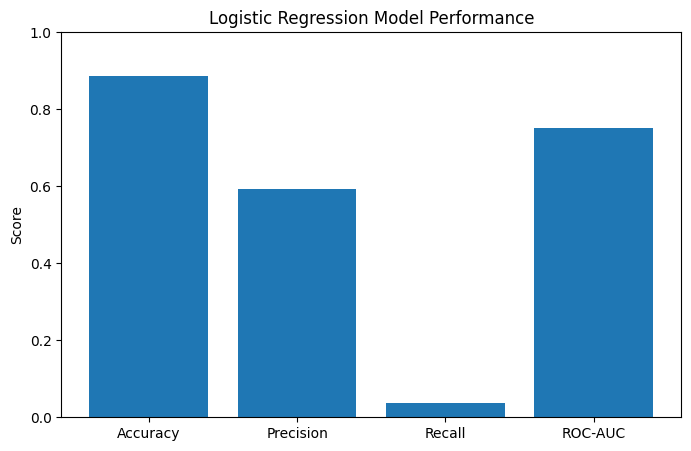

In [64]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "ROC-AUC": roc_auc
}

plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), metrics.values())
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Logistic Regression Model Performance")
plt.show()

In [65]:
# Model does not identify all the defaults correctly, find a different threshold to train
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

threshold = 0.25

y_pred_custom = (y_proba >= threshold).astype(int)

print("Precision:", precision_score(y_test, y_pred_custom))
print("Recall:", recall_score(y_test, y_pred_custom))
print("F1:", f1_score(y_test, y_pred_custom))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom))

Precision: 0.3480859010270775
Recall: 0.3142808969819592
F1: 0.33032075137338296
Confusion Matrix:
[[41648  3491]
 [ 4067  1864]]


In [66]:
# Test for other thresholds to see what is better, lowering thresholds
for threshold in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]:
    y_pred_custom = (y_proba >= threshold).astype(int)
    print("Threshold:", threshold)
    print("Precision:", precision_score(y_test, y_pred_custom))
    print("Recall:", recall_score(y_test, y_pred_custom))
    print("F1:", f1_score(y_test, y_pred_custom))
    print(confusion_matrix(y_test, y_pred_custom))
    print()

Threshold: 0.1
Precision: 0.2033302919708029
Recall: 0.7514752992749958
F1: 0.32006032099386017
[[27676 17463]
 [ 1474  4457]]

Threshold: 0.15
Precision: 0.2536301319377902
Recall: 0.5801719777440566
F1: 0.3529592778746538
[[35013 10126]
 [ 2490  3441]]

Threshold: 0.2
Precision: 0.3011850287457468
Recall: 0.4328106558759063
F1: 0.35519579355195796
[[39183  5956]
 [ 3364  2567]]

Threshold: 0.25
Precision: 0.3480859010270775
Recall: 0.3142808969819592
F1: 0.33032075137338296
[[41648  3491]
 [ 4067  1864]]

Threshold: 0.3
Precision: 0.3945619335347432
Recall: 0.22019895464508515
F1: 0.2826533924899903
[[43135  2004]
 [ 4625  1306]]

Threshold: 0.4
Precision: 0.4829821717990275
Recall: 0.10048895633114147
F1: 0.166364270760642
[[44501   638]
 [ 5335   596]]

Threshold: 0.5
Precision: 0.5929919137466307
Recall: 0.03709323891417973
F1: 0.06981910504601714
[[44988   151]
 [ 5711   220]]



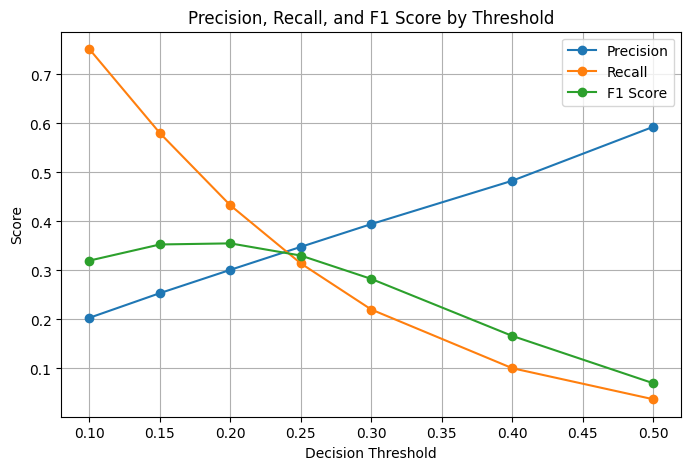

In [67]:
# Chose the model based on F1 score
# F1 = 2 × (Precision × Recall) / (Precision + Recall)
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]

precisions = []
recalls = []
f1_scores = []

for threshold in thresholds:
    y_pred_custom = (y_proba >= threshold).astype(int)

    precisions.append(precision_score(y_test, y_pred_custom))
    recalls.append(recall_score(y_test, y_pred_custom))
    f1_scores.append(f1_score(y_test, y_pred_custom))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, marker="o", label="Precision")
plt.plot(thresholds, recalls, marker="o", label="Recall")
plt.plot(thresholds, f1_scores, marker="o", label="F1 Score")

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, and F1 Score by Threshold")
plt.legend()
plt.grid(True)
plt.show()

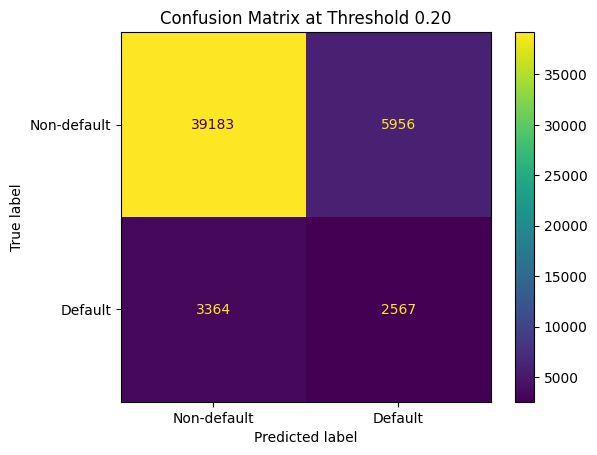

In [68]:
# Display Confusion Matrix that shows TN FP FN TP
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

threshold = 0.20
y_pred_020 = (y_proba >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_020)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-default", "Default"]
)

disp.plot()
plt.title("Confusion Matrix at Threshold 0.20")
plt.show()

## Threshold Tuning

Because the dataset is imbalanced, the default classification threshold of 0.50 produced very low recall. I tested multiple thresholds from 0.10 to 0.50 and compared precision, recall, and F1 score.

Lower thresholds increased recall but reduced precision, while higher thresholds increased precision but missed more defaulters. The threshold of 0.20 gave the best F1 score, making it the strongest balanced choice for this MVP model.

At threshold 0.20, the model correctly identified 2,567 defaulters, compared to only 220 defaulters at the default threshold of 0.50.

In [69]:
# Use Random Forest that can catch features like low income + high loan amount + high interest rate
# Number of estimators is the amount of decision trees 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_proba = rf_model.predict_proba(X_test)[:, 1]

In [70]:
# Compare with all thresholds
thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]

rf_precisions = []
rf_recalls = []
rf_f1_scores = []

for threshold in thresholds:
    rf_pred = (rf_proba >= threshold).astype(int)

    precision = precision_score(y_test, rf_pred)
    recall = recall_score(y_test, rf_pred)
    f1 = f1_score(y_test, rf_pred)

    rf_precisions.append(precision)
    rf_recalls.append(recall)
    rf_f1_scores.append(f1)

    print("Threshold:", threshold)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1:", f1)
    print("ROC-AUC:", roc_auc_score(y_test, rf_proba))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, rf_pred))
    print()

Threshold: 0.1
Precision: 0.18813131313131312
Recall: 0.753667172483561
F1: 0.30110134384156817
ROC-AUC: 0.7311337165696492
Confusion Matrix:
[[25849 19290]
 [ 1461  4470]]

Threshold: 0.15
Precision: 0.24193548387096775
Recall: 0.56398583712696
F1: 0.3386141620691401
ROC-AUC: 0.7311337165696492
Confusion Matrix:
[[34658 10481]
 [ 2586  3345]]

Threshold: 0.2
Precision: 0.30013971802362505
Recall: 0.39841510706457595
F1: 0.34236453201970446
ROC-AUC: 0.7311337165696492
Confusion Matrix:
[[39629  5510]
 [ 3568  2363]]

Threshold: 0.25
Precision: 0.362429696287964
Recall: 0.2716236722306525
F1: 0.3105242868157286
ROC-AUC: 0.7311337165696492
Confusion Matrix:
[[42305  2834]
 [ 4320  1611]]

Threshold: 0.3
Precision: 0.40940695296523516
Recall: 0.1687742370595178
F1: 0.23901623686723975
ROC-AUC: 0.7311337165696492
Confusion Matrix:
[[43695  1444]
 [ 4930  1001]]

Threshold: 0.4
Precision: 0.5311143270622286
Recall: 0.06187826673410892
F1: 0.11084264572636665
ROC-AUC: 0.7311337165696492
Conf

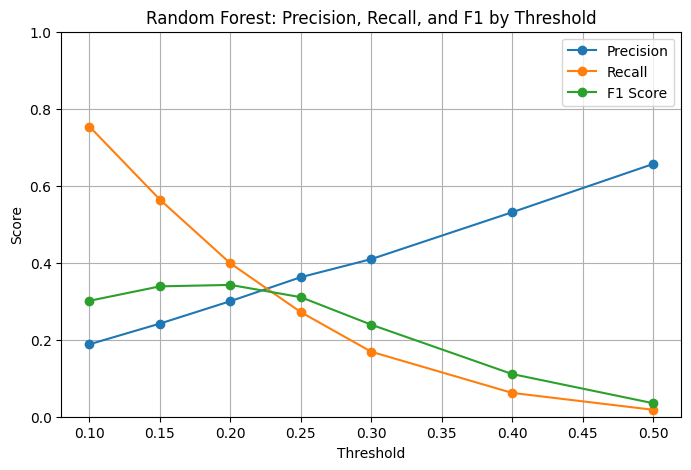

In [71]:
# Visualize to see the best threshold
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(thresholds, rf_precisions, marker="o", label="Precision")
plt.plot(thresholds, rf_recalls, marker="o", label="Recall")
plt.plot(thresholds, rf_f1_scores, marker="o", label="F1 Score")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Random Forest: Precision, Recall, and F1 by Threshold")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

## Random Forest Results

I trained a Random Forest model to compare against the Logistic Regression baseline. Random Forest can capture nonlinear relationships and feature interactions, but in this experiment it did not outperform Logistic Regression.

The best Random Forest threshold was 0.20, with an F1 score of 0.342 and ROC-AUC of 0.731. Logistic Regression performed better with an F1 score of 0.355 and ROC-AUC of 0.750 at the same threshold.

Because Logistic Regression had better recall, F1 score, and ROC-AUC, it remains the stronger model for this MVP.

In [72]:
# Compare between Logistic Regression and Random Forest
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Best Threshold": [0.20, 0.20],
    "Precision": [0.301, 0.300],
    "Recall": [0.433, 0.398],
    "F1 Score": [0.355, 0.342],
    "ROC-AUC": [0.750, 0.731]
})

comparison

,Model,Best Threshold,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.2,0.301,0.433,0.355,0.750
1,Random Forest,0.2,0.300,0.398,0.342,0.731


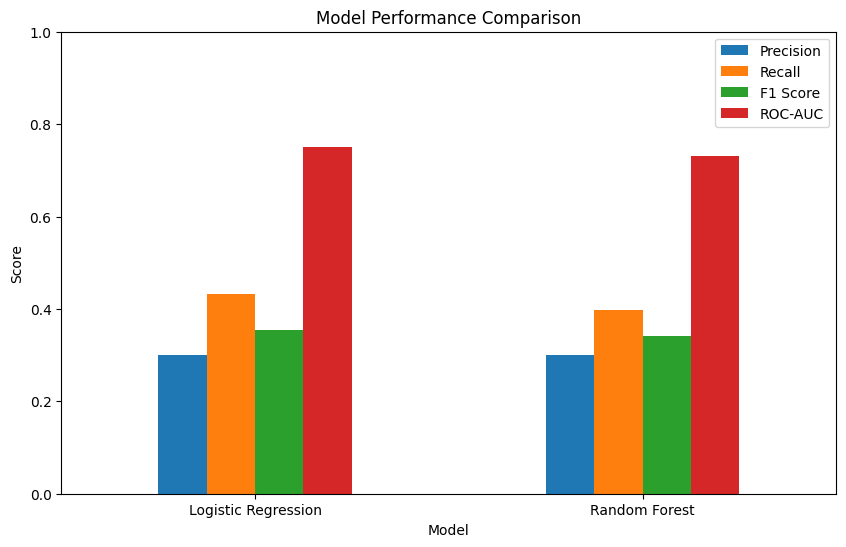

In [73]:
import matplotlib.pyplot as plt

comparison.set_index("Model")[["Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [74]:
# Use XGBoost as a new machine learning algorithim

from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

In [75]:
# Test with all thresholds

thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]

for threshold in thresholds:
    xgb_pred = (xgb_proba >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Precision:", precision_score(y_test, xgb_pred))
    print("Recall:", recall_score(y_test, xgb_pred))
    print("F1:", f1_score(y_test, xgb_pred))
    print("ROC-AUC:", roc_auc_score(y_test, xgb_proba))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, xgb_pred))
    print()

Threshold: 0.1
Precision: 0.2040078693324793
Recall: 0.7518125105378519
F1: 0.3209298977976105
ROC-AUC: 0.7531294733285475
Confusion Matrix:
[[27741 17398]
 [ 1472  4459]]

Threshold: 0.15
Precision: 0.26134512450546893
Recall: 0.5680323722812342
F1: 0.3579853363085751
ROC-AUC: 0.7531294733285475
Confusion Matrix:
[[35617  9522]
 [ 2562  3369]]

Threshold: 0.2
Precision: 0.3120224146714213
Recall: 0.41308379699881975
F1: 0.35551041137633316
ROC-AUC: 0.7531294733285475
Confusion Matrix:
[[39737  5402]
 [ 3481  2450]]

Threshold: 0.25
Precision: 0.3715858564471734
Recall: 0.2959028831562974
F1: 0.3294537262999812
ROC-AUC: 0.7531294733285475
Confusion Matrix:
[[42171  2968]
 [ 4176  1755]]

Threshold: 0.3
Precision: 0.42063216394581454
Recall: 0.20418141965941664
F1: 0.27491486946651533
ROC-AUC: 0.7531294733285475
Confusion Matrix:
[[43471  1668]
 [ 4720  1211]]

Threshold: 0.4
Precision: 0.5342995169082125
Recall: 0.09323891417973361
F1: 0.15877117427505025
ROC-AUC: 0.7531294733285475
Co

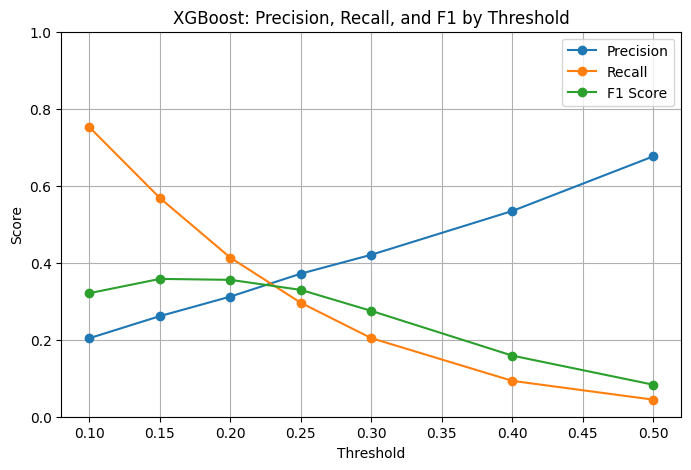

In [76]:
# Visualize data to see if XGBoost is better than Logistic Regression

import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]

xgb_precisions = []
xgb_recalls = []
xgb_f1_scores = []

for threshold in thresholds:
    xgb_pred = (xgb_proba >= threshold).astype(int)

    xgb_precisions.append(precision_score(y_test, xgb_pred))
    xgb_recalls.append(recall_score(y_test, xgb_pred))
    xgb_f1_scores.append(f1_score(y_test, xgb_pred))

plt.figure(figsize=(8, 5))

plt.plot(thresholds, xgb_precisions, marker="o", label="Precision")
plt.plot(thresholds, xgb_recalls, marker="o", label="Recall")
plt.plot(thresholds, xgb_f1_scores, marker="o", label="F1 Score")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("XGBoost: Precision, Recall, and F1 by Threshold")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

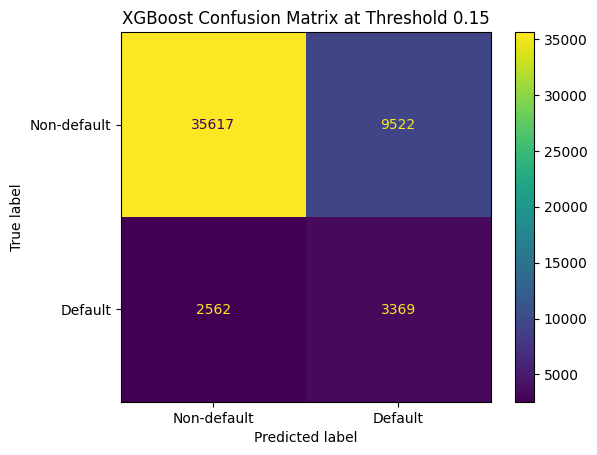

In [77]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

threshold = 0.15
xgb_pred_015 = (xgb_proba >= threshold).astype(int)

cm = confusion_matrix(y_test, xgb_pred_015)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-default", "Default"]
)

disp.plot()
plt.title("XGBoost Confusion Matrix at Threshold 0.15")
plt.show()

## XGBoost Results

I trained an XGBoost model as a stronger gradient-boosted tree model for loan default prediction. XGBoost performed slightly better than both Logistic Regression and Random Forest.

The best XGBoost threshold was 0.15, with an F1 score of 0.358 and ROC-AUC of 0.753. This model had lower precision than Logistic Regression, but it had much higher recall, meaning it caught more actual defaulters.

For this MVP, XGBoost at threshold 0.15 is the selected model because it provides the best balance overall and catches the most risky borrowers.

In [78]:
# Test the whole dataset using the selected XGBoost model

import pandas as pd

features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio",
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

X_all = df[features]
y_all = df["Default"]

X_all_encoded = pd.get_dummies(X_all, drop_first=True)

X_all_encoded = X_all_encoded.reindex(columns=X_train.columns, fill_value=0)

all_proba = xgb_model.predict_proba(X_all_encoded)[:, 1]

def risk_decision(probability):
    if probability < 0.15:
        return "Low Risk"
    elif probability < 0.40:
        return "Medium Risk - Manual Review"
    else:
        return "High Risk"

results = df.copy()
results["Predicted_Default_Probability"] = all_proba
results["Risk_Decision"] = results["Predicted_Default_Probability"].apply(risk_decision)

results_view = results[
    [
        "Age",
        "Income",
        "LoanAmount",
        "CreditScore",
        "InterestRate",
        "DTIRatio",
        "Default",
        "Predicted_Default_Probability",
        "Risk_Decision"
    ]
]

results_view.head(20)

,Age,Income,LoanAmount,CreditScore,InterestRate,DTIRatio,Default,Predicted_Default_Probability,Risk_Decision
0,56,85994,50587,520,15.23,0.44,0,0.038698,Low Risk
1,69,50432,124440,458,4.81,0.68,0,0.036109,Low Risk
2,46,84208,129188,451,21.17,0.31,1,0.208760,Medium Risk - Manual Review
3,32,31713,44799,743,7.07,0.23,0,0.150031,Medium Risk - Manual Review
4,60,20437,9139,633,6.51,0.73,0,0.058146,Low Risk
5,25,90298,90448,720,22.72,0.10,1,0.326348,Medium Risk - Manual Review
6,38,111188,177025,429,19.11,0.16,0,0.111508,Low Risk
7,56,126802,155511,531,8.15,0.43,0,0.029818,Low Risk
8,36,42053,92357,827,23.94,0.20,1,0.157488,Medium Risk - Manual Review
9,40,132784,228510,480,9.09,0.33,0,0.050624,Low Risk


In [79]:
results["Risk_Decision"].value_counts()

Risk_Decision
Low Risk                       191236
Medium Risk - Manual Review     58996
High Risk                        5115
Name: count, dtype: int64

In [80]:
results["Risk_Decision"].value_counts(normalize=True) * 100

Risk_Decision
Low Risk                       74.892597
Medium Risk - Manual Review    23.104246
High Risk                       2.003156
Name: proportion, dtype: float64

In [81]:
results.groupby("Risk_Decision")["Default"].mean().sort_values(ascending=False)

Risk_Decision
High Risk                      0.564027
Medium Risk - Manual Review    0.240898
Low Risk                       0.065657
Name: Default, dtype: float64

## Risk Category Validation

After selecting the XGBoost model, I applied the model to the full dataset and converted predicted default probabilities into three risk categories: Low Risk, Medium Risk - Manual Review, and High Risk.

The risk categories showed a clear separation in actual default rates:

- Low Risk: 6.57% default rate
- Medium Risk: 24.09% default rate
- High Risk: 56.40% default rate

This confirms that the model’s risk scores are meaningful. Applicants labeled High Risk defaulted far more often than applicants labeled Low Risk, while Medium Risk applicants fell between the two groups.

Because of this, the model is useful as an MVP risk-screening tool rather than a fully automated approval system.

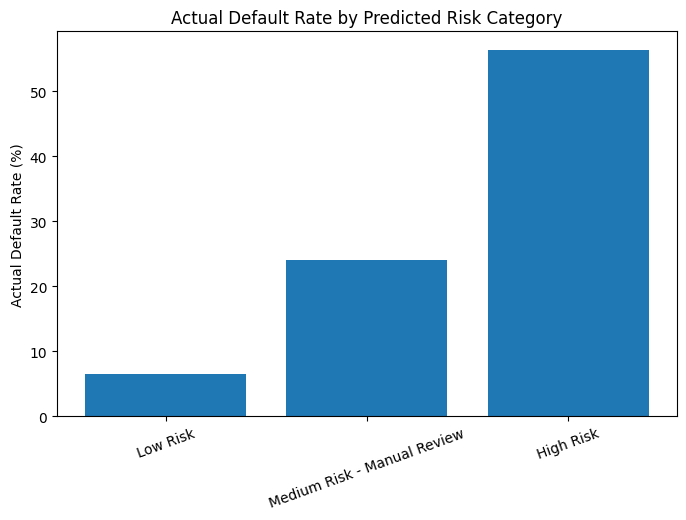

In [82]:
import matplotlib.pyplot as plt

risk_default_rates = results.groupby("Risk_Decision")["Default"].mean() * 100

risk_default_rates = risk_default_rates.reindex([
    "Low Risk",
    "Medium Risk - Manual Review",
    "High Risk"
])

plt.figure(figsize=(8, 5))
plt.bar(risk_default_rates.index, risk_default_rates.values)
plt.ylabel("Actual Default Rate (%)")
plt.title("Actual Default Rate by Predicted Risk Category")
plt.xticks(rotation=20)
plt.show()

In [83]:
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, roc_auc_score

xgb_tuned = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_tuned.fit(X_train, y_train)

xgb_tuned_proba = xgb_tuned.predict_proba(X_test)[:, 1]

threshold = 0.15
xgb_tuned_pred = (xgb_tuned_proba >= threshold).astype(int)

print("F1:", f1_score(y_test, xgb_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_tuned_proba))

F1: 0.3606015358361775
ROC-AUC: 0.7531742347451544


## Different Selected Model

After comparing Logistic Regression, Decision Tree, Random Forest, XGBoost, LightGBM, and a tuned XGBoost model, I selected the tuned XGBoost model with a threshold of 0.15.

The tuned XGBoost model achieved the best F1 score of 0.361 and ROC-AUC of 0.753. This made it the strongest model for the MVP risk-screening system.

In [84]:
# Check the best threshold starting from 0.5.
from sklearn.metrics import precision_score, recall_score, f1_score

best_threshold = None
best_f1 = 0

for threshold in [i / 100 for i in range(5, 100)]:
    pred = (xgb_tuned_proba >= threshold).astype(int)
    f1 = f1_score(y_test, pred)

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)

Best threshold: 0.17
Best F1: 0.3628625281206299


In [85]:
# 0.17 is the best based on the F1 score,

from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

final_threshold = 0.17

final_pred = (xgb_tuned_proba >= final_threshold).astype(int)

print("Precision:", precision_score(y_test, final_pred))
print("Recall:", recall_score(y_test, final_pred))
print("F1:", f1_score(y_test, final_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_tuned_proba))
print("Confusion Matrix:")
print(confusion_matrix(y_test, final_pred))

Precision: 0.2837580829212628
Recall: 0.5031192041814196
F1: 0.3628625281206299
ROC-AUC: 0.7531742347451544
Confusion Matrix:
[[37607  7532]
 [ 2947  2984]]


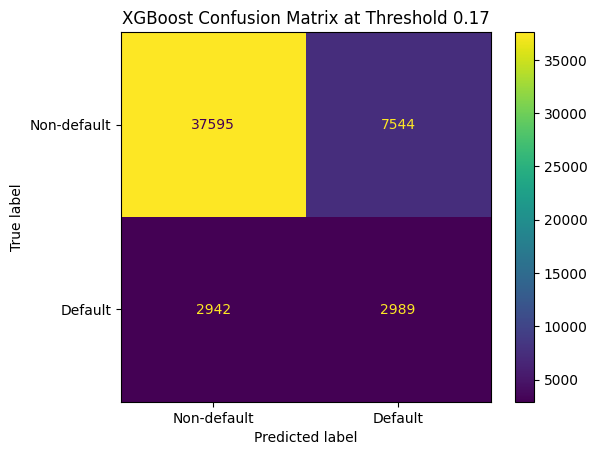

In [86]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

threshold = 0.17
xgb_pred_015 = (xgb_proba >= threshold).astype(int)

cm = confusion_matrix(y_test, xgb_pred_015)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-default", "Default"]
)

disp.plot()
plt.title("XGBoost Confusion Matrix at Threshold 0.17")
plt.show()

## Final Selected Model

The final selected model is the tuned XGBoost model with a decision threshold of 0.17.

After threshold tuning, the best F1 score improved to 0.363. This threshold gave the best balance between precision and recall for the MVP risk-screening system.

In [87]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(xgb_tuned, "models/xgb_loan_default_model.pkl")
joblib.dump(list(X_train.columns), "models/model_columns.pkl")
joblib.dump(0.17, "models/final_threshold.pkl")

['models/final_threshold.pkl']

In [97]:
# Provide an explanity first for each feature
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_tuned.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance.head(15)

,Feature,Importance
0,Age,0.208039
6,InterestRate,0.115293
1,Income,0.098748
4,MonthsEmployed,0.073807
2,LoanAmount,0.073221
23,HasCoSigner_Yes,0.047899
18,HasDependents_Yes,0.046633
13,EmploymentType_Self-employed,0.045542
14,EmploymentType_Unemployed,0.042001
15,MaritalStatus_Married,0.031245


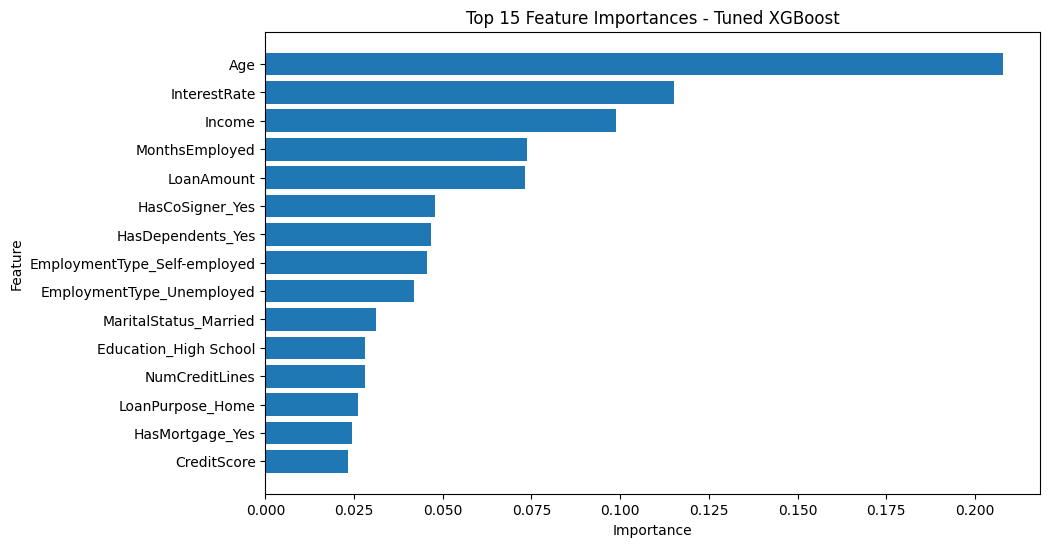

In [95]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Tuned XGBoost")
plt.gca().invert_yaxis()
plt.show()

### Explainability

To make the tuned XGBoost model more interpretable, I analyzed feature importance. Feature importance shows which variables had the greatest influence on the model's predictions.

The most important feature was Age, followed by InterestRate, Income, MonthsEmployed, and LoanAmount. These features are reasonable for a loan default prediction problem because they relate to borrower stability, loan affordability, and repayment risk.

Employment-related features such as MonthsEmployed, EmploymentType_Self-employed, and EmploymentType_Unemployed also appeared in the top features, showing that the model considers employment stability when estimating default risk.

Co-signer and dependent status also influenced predictions, which makes sense because they may affect repayment responsibility and financial obligations.

This explainability step helps make the model less of a black box. In a production lending system, more advanced tools such as SHAP or LIME would be needed to explain individual predictions and support compliance, audits, and fair lending review.

In [110]:
# Bias and Fairness Checks

import pandas as pd

# Rebuild results using the original unencoded test rows
# This gives us readable columns like Education, EmploymentType, MaritalStatus, etc.
fairness_df = df.loc[X_test.index].copy()

fairness_df["Actual_Default"] = y_test.values
fairness_df["Predicted_Default_Probability"] = xgb_tuned_proba
fairness_df["Risk_Decision"] = fairness_df["Predicted_Default_Probability"].apply(risk_decision)

# Create age groups
fairness_df["Age_Group"] = pd.cut(
    fairness_df["Age"],
    bins=[18, 30, 45, 60, 100],
    labels=["18-30", "31-45", "46-60", "60+"],
    include_lowest=True
)

# Create income groups
fairness_df["Income_Group"] = pd.cut(
    fairness_df["Income"],
    bins=[0, 40000, 80000, 120000, 200000],
    labels=["Low Income", "Middle Income", "Upper Middle Income", "High Income"],
    include_lowest=True
)

print("Average Predicted Default Probability by Age Group")
print(fairness_df.groupby("Age_Group", observed=False)["Predicted_Default_Probability"].mean())
print("\n")

print("Actual Default Rate by Age Group")
print(fairness_df.groupby("Age_Group", observed=False)["Actual_Default"].mean())
print("\n")

print("Risk Decision Distribution by Age Group (%)")
print(
    pd.crosstab(
        fairness_df["Age_Group"],
        fairness_df["Risk_Decision"],
        normalize="index"
    ) * 100
)
print("\n")

print("Average Predicted Default Probability by Income Group")
print(fairness_df.groupby("Income_Group", observed=False)["Predicted_Default_Probability"].mean())
print("\n")

print("Actual Default Rate by Income Group")
print(fairness_df.groupby("Income_Group", observed=False)["Actual_Default"].mean())
print("\n")

print("Risk Decision Distribution by Income Group (%)")
print(
    pd.crosstab(
        fairness_df["Income_Group"],
        fairness_df["Risk_Decision"],
        normalize="index"
    ) * 100
)
print("\n")

print("Average Predicted Default Probability by Education")
print(fairness_df.groupby("Education")["Predicted_Default_Probability"].mean())
print("\n")

print("Average Predicted Default Probability by Employment Type")
print(fairness_df.groupby("EmploymentType")["Predicted_Default_Probability"].mean())
print("\n")

print("Average Predicted Default Probability by Marital Status")
print(fairness_df.groupby("MaritalStatus")["Predicted_Default_Probability"].mean())
print("\n")

print("Risk Decision Distribution by Employment Type (%)")
print(
    pd.crosstab(
        fairness_df["EmploymentType"],
        fairness_df["Risk_Decision"],
        normalize="index"
    ) * 100
)

Average Predicted Default Probability by Age Group
Age_Group
18-30    0.189137
31-45    0.127549
46-60    0.078992
60+      0.055606
Name: Predicted_Default_Probability, dtype: float32


Actual Default Rate by Age Group
Age_Group
18-30    0.196776
31-45    0.125086
46-60    0.076876
60+      0.050606
Name: Actual_Default, dtype: float64


Risk Decision Distribution by Age Group (%)
Risk_Decision  High Risk   Low Risk  Medium Risk - Manual Review
Age_Group                                                       
18-30           5.539473  53.290040                    41.170487
31-45           1.915971  77.658410                    20.425619
46-60           0.539011  92.952432                     6.508557
60+             0.101891  97.339522                     2.558587


Average Predicted Default Probability by Income Group
Income_Group
Low Income             0.187508
Middle Income          0.110021
Upper Middle Income    0.095697
High Income            0.092931
Name: Predicted_Default_Prob